Экзамен: **Анализ Данных**

Выполнил: **Белоцерковский Даниил Валерьевич**

## 0. Подготовка и ЗАГРУЗКА ФАЙЛОВ

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

pd.set_option('display.precision', 3)   # три знака после запятой, как в примерах

**Скрипт, чтобы загрузить файлы прямо в ноутбук. Либо же можно сразу добавить их в раздел "файлы". Используются для заданий данные из DATA.**


In [2]:
DATA = 'NHL-playoffs-2026.xlsx'

missing = [f for f in [DATA, 'rink.py'] if not os.path.exists(f)]
if missing:
    try:
        from google.colab import files
        print('Загрузите файлы:', ', '.join(missing))
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'Положите рядом с ноутбуком: {missing}')

from rink import plot_rink

## 1. Прочитайте данные из файла NHL-playoffs-2026.xlsx в набор данных pandas.

Первый столбец файла хранит номер строки, поэтому делаем его индексом (`index_col=0`).
Тогда в таблице 38 столбцов, как в примере.

In [3]:
events = pd.read_excel(DATA, index_col=0)
events.shape

(29710, 38)

In [4]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


## 2. Соберите краткую сводную информацию по каждой игре в отдельный набор данных pandas. В таблице должны быть дата, названия команд, сколько голов они забили и сколько овертаймов понадобилось, если таковые были.

Каждая строка `events` описывает одно событие, поэтому группируем события по `Game ID`:
все строки одного матча попадают в одну группу. Из каждой группы берём:

* **дату и названия команд**: они одинаковы во всех строках матча, поэтому берём первое значение (`first`);
* **итоговый счёт**: поля `Cumulated Away Score` и `Cumulated Home Score` хранят счёт на момент события и со временем только растут, поэтому максимум по матчу равен итоговому счёту (`max`);
* **число овертаймов**: основное время состоит из трёх периодов, всё после третьего считается овертаймом. Смотрим номер последнего периода матча:
  * 3 -> `Final` (победитель определился в основное время);
  * 4 -> `Final/OT` (один овертайм);
  * 5 -> `Final/2OT` (два овертайма), и так далее: число овертаймов = последний период − 3.

In [5]:
g = events.groupby('Game ID')   # все события одного матча в одной группе

games = pd.DataFrame({
    'Date':       g['Date'].first(),                   # дата одинакова во всех строках матча
    'Away Team':  g['Away Team'].first(),
    'Home Team':  g['Home Team'].first(),
    'Away Score': g['Cumulated Away Score'].max(),     # счёт только растёт, максимум = итог
    'Home Score': g['Cumulated Home Score'].max(),
})

def outcome(last_period):
    if last_period <= 3:
        return 'Final'                        # победитель определился в основное время
    if last_period == 4:
        return 'Final/OT'                     # один овертайм
    return f'Final/{last_period - 3}OT'       # несколько овертаймов

games['Outcome'] = g['Period'].max().apply(outcome)
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')

In [6]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


## 3. Так как в последующих заданиях часто будет необходимо вывести информацию о какой-нибудь игре, напишите функцию gameInfo(gameId), которая бы возвращала её, скажем, как в следующем примере:

```
In [1]: gameInfo(games.index.min())
Out[1]: Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
In [2]: gameInfo(games.index.max())
Out[2]: Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-
14)
```



In [7]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Сосчитайте, сколько всего было забито шайб в каждой игре (поля Away Score и Home Scoreв таблице matches) и выведите описательные статистики для этого показателя. Пример:

```
In [1]: games[’Total Score’].describe()
Out[1]:
count 82.000
mean 5.927
std 2.260
min 1.000
25% 5.000
50% 6.000
75% 7.000
max 15.000
Name: Total Score, dtype: float64
```



In [8]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

**Вывод.** В среднем 5,93 гола за матч, медиана 6. В половине матчей забивали от 5 до 7 голов.
Минимум 1 гол, максимум 15.

## 5. Гистограмма числа голов

Число голов дискретно, поэтому используем `countplot`. Параметр `order` показывает
и пустые значения 12, 13, 14.

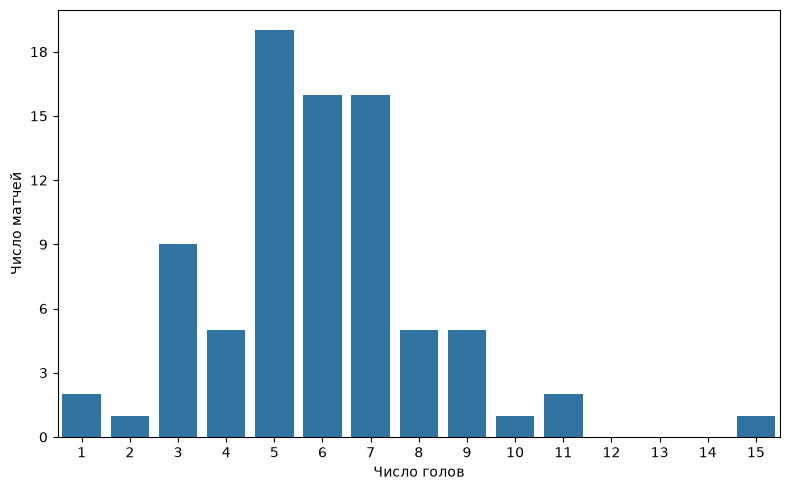

In [9]:
plt.figure(figsize=(8, 5))
order = range(games['Total Score'].min(), games['Total Score'].max() + 1)
ax = sns.countplot(x=games['Total Score'], order=order, color='tab:blue')
ax.set_xlabel('Число голов')
ax.set_ylabel('Число матчей')
ax.yaxis.set_major_locator(plt.MultipleLocator(3))
plt.tight_layout()
plt.show()

**Вывод.** Чаще всего забивали 5 голов (19 матчей), затем 6 и 7 (по 16). Распределение скошено вправо: меньше 1 гола в плей-офф быть не может, а справа есть редкие матчи на 10, 11 и 15 голов.


## 6. Самые нерезультативные и самые результативные матчи

In [10]:
least = games.index[games['Total Score'] == games['Total Score'].min()]
most  = games.index[games['Total Score'] == games['Total Score'].max()]
print([gameInfo(g) for g in least])
print([gameInfo(g) for g in most])

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


**Вывод.** Оба самых нерезультативных матча закончились 1:0 в овертайме: в основное время никто
не забивал. В самом результативном матче, Colorado - Minnesota (9:6), забили 15 голов,
в 2,5 раза больше среднего из п. 4.

## 7. Сколько игроков участвовало в матче

Собираем фамилии из всех столбцов состава (включая вратарей) и считаем уникальные значения в каждом матче.

## Пустые ячейки не считаем (если считать пустые ячейки, то получается ответ как в примере = 41, я расписал этот момент ниже).

In [11]:
onice_cols = [c for c in events.columns
              if 'on the Ice #' in c
              or c.endswith('Goalie')]                   # + вратари (их названия кончаются на Goalie)

players_long = (events.melt(id_vars='Game ID',           # все фамилии в один столбец:
                            value_vars=onice_cols,       #   одна строка = (матч, игрок)
                            value_name='Player')
                      .dropna(subset=['Player']))        # убираем пустые ячейки (NaN) !!!

player_count = players_long.groupby('Game ID')['Player'].nunique()   # разные игроки в каждом матче

top = player_count[player_count == player_count.max()]   # матчи с максимумом игроков
pd.DataFrame({'Game Info': top.index.map(gameInfo),      # описание матча
              'Player Count': top})                      # число игроков

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


**Вывод.** Больше всего игроков (40) участвовало в матче Montréal - Buffalo (3:8).
В заявке команды 20 человек (18 полевых и 2 вратаря), значит, в этом матче сыграли все:
обе команды меняли вратаря.

В примере из условия указано 41: так получается, если посчитать пустое значение `NaN`
ещё одним игроком (проверка ниже). Правильный ответ 40.

In [12]:
# С учётом NaN получается 41, как в примере
len(pd.unique(events.loc[events['Game ID'] == top.index[0], onice_cols].values.ravel()))

41

## 8. Расстояние до ворот

Броски: `shot-on-goal`, `goal` (точные) и `missed-shot` (неточные).

Какие ворота атакует команда:
* `Home Team's Defending Side == 'left'`: хозяева бьют в правые ворота ($X=89$), гости в левые ($X=-89$);
* `right`: наоборот.


Расстояние от точки броска до ближайшей точки створа ворот:

$
d(x, y) =
\begin{cases}
\sqrt{(x - X)^2 + (y + 3)^2}, & \text{если } y < -3,\\[4pt]
|x - X|, & \text{если } -3 \le y \le 3,\\[4pt]
\sqrt{(x - X)^2 + (y - 3)^2}, & \text{если } y > 3.
\end{cases}$.


In [13]:
def goal_x(row):
    home_shoots = row['Team Making the Play'] == row['Home Team']   # бросают хозяева?
    if row["Home Team's Defending Side"] == 'left':                 # хозяева защищают левые ворота
        return 89 if home_shoots else -89                           # хозяева бьют в правые, гости в левые
    else:                                                           # хозяева защищают правые ворота
        return -89 if home_shoots else 89                           # хозяева бьют в левые, гости в правые


def shot_length(row):
    x = row['X Coordinate on the Ice Rink']
    y = row['Y Coordinate on the Ice Rink']
    X = row['Goal X']
    if y < -3:                                    # бросок ниже ворот
        return np.sqrt((x - X)**2 + (y + 3)**2)
    elif y > 3:                                   # бросок выше ворот
        return np.sqrt((x - X)**2 + (y - 3)**2)
    else:                                         # бросок напротив ворот
        return abs(x - X)


events['Goal X'] = events.apply(goal_x, axis=1)             # X ворот, в которые бросают
events['Shot Length'] = events.apply(shot_length, axis=1)   # расстояние до ворот

shot_types = ['shot-on-goal', 'goal', 'missed-shot']
events[events['Play Type'].isin(shot_types)][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


**Вывод.** Получилось 7266 бросков, значения совпадают с примером из условия.

## 9. Сравните распределение длины точных и неточных бросков.

Есть три типа бросков:


1.   shot-on-goal - бросок в створ, вратарь отбил -> группа on goal (точный)
2.   goal — гол -> группа on goal (точный)
3.   missed-shot — бросок мимо ворот -> группа missed (неточный)


Чтобы сравнить форму распределений, а не количество,
строим плотность (`stat='density'`) и нормируем каждую группу отдельно (`common_norm=False`).

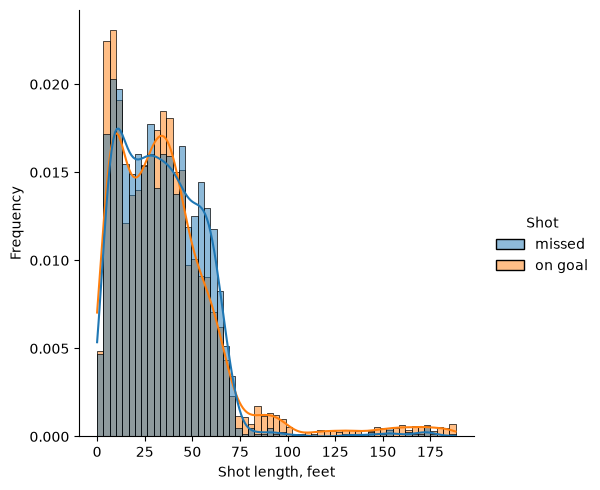

In [14]:
shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()   # только броски

# делим броски на две группы
group = {
    'shot-on-goal': 'on goal',   # бросок в створ, вратарь отбил
    'goal':         'on goal',   # гол
    'missed-shot':  'missed',    # бросок мимо ворот
}
shots['Shot'] = shots['Play Type'].map(group)

# две гистограммы длины бросков: точные и неточные
sns.displot(data=shots, x='Shot Length', hue='Shot',   # цвет = группа
            stat='density', common_norm=False,         # каждую группу нормируем отдельно
            kde=True)                                  # сглаженная кривая
plt.xlabel('Shot length, feet')
plt.ylabel('Frequency')
plt.show()

**Вывод.**
* Вблизи ворот (5-10 футов) точных бросков заметно больше: добивания и подставления почти всегда идут в створ.
* На средних дистанциях (примерно 45-70 футов, броски от синей линии) чаще промахиваются.
* У точных бросков есть длинный хвост дальше 89 футов, то есть со своей половины площадки.

**Почему такой хвост?** Это в основном не броски по воротам, а выбросы шайбы из своей зоны. Если вратарь поймал такой выброс, он считается броском в створ, а если шайба прошла мимо ворот, это записывают как проброс, а не как бросок мимо.

## 10. Сосчитайте долю точных бросков среди всех незаблокированных бросков у каждой команды в каждой игре.

Берём только незаблокированные броски (`shot-on-goal`, `goal`, `missed-shot`). Доля = точные / все незаблокированные.

In [15]:
shots['On Goal'] = shots['Shot'] == 'on goal'   # True, если бросок в створ; False, если мимо

# доля бросков в створ у каждой команды в каждом матче
numshots = (shots.groupby(['Game ID', 'Team Making the Play'])['On Goal']
                 .mean()
                 .to_frame('Share of Shots on Goal'))
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

**Вывод.** В показанных матчах доля точных бросков от 0,51 до 0,69: примерно 2 из 3
незаблокированных бросков идут в створ, остальные мимо. Доля заметно меняется от матча
к матчу даже у одной команды (у Boston 0,625, 0,614 и 0,694 в трёх матчах подряд),
поэтому по одному матчу о точности команды судить сложно.

## 11. Найдите и выведите по пять команд с самыми высокими и самыми низкими средними долями точных бросков за матч.

In [16]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [17]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

**Вывод.** Самая точная команда Edmonton (70,6 %), наименее точная Pittsburgh (55,4 %). Высокая точность не гарантирует успеха: финалист Carolina в пятёрке наименее точных.

## 12. Сосчитайте среднее число бросков в створ ворот и среднее число голов за игру для каждой из 16 команд-участниц плей-офф.

По правилам НХЛ бросок в створ включает и голы, поэтому `Shot = shot-on-goal + goal`.
`crosstab` ставит 0, если событий не было, так что матчи без голов тоже учитываются.

In [18]:
per_game = pd.crosstab([events['Game ID'], events['Team Making the Play']], events['Play Type'])
per_game = per_game.assign(Shot=per_game['shot-on-goal'] + per_game['goal'],
                           Goal=per_game['goal'])[['Shot', 'Goal']]

avgshots = per_game.groupby('Team Making the Play').mean()
avgshots

Play Type,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


**Вывод.** Больше всех бросали Colorado (32,2 за матч), Anaheim и Carolina. Меньше всех бросал
Montréal (23,3), но забивал 2,84 гола за матч, то есть реализация очень высокая.
Больше всех забивала Minnesota (3,73), меньше всех Los Angeles и Ottawa (по 1,25).

## 13. Связь бросков и голов

`regplot` по 16 командам. Подписаны команды, которые выделяются (как в примере из условия).

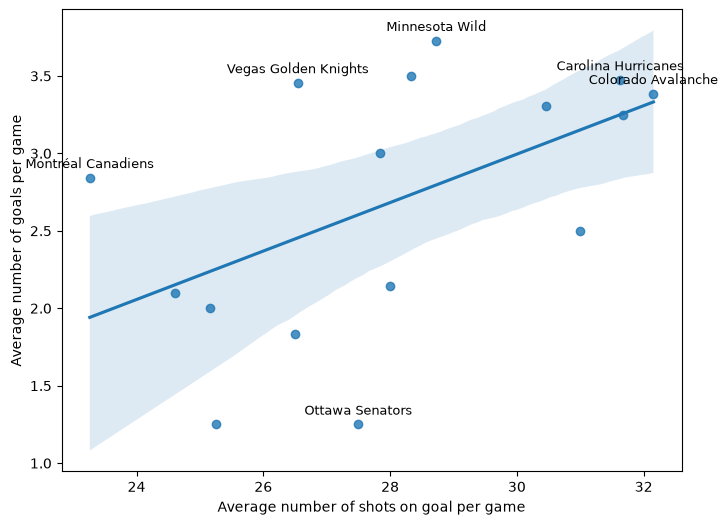

In [19]:
plt.figure(figsize=(8, 6))
sns.regplot(data=avgshots, x='Shot', y='Goal')   # точки команд и линия регрессии

# подписываем только команды, которые выделяются (как в примере из условия)
teams = ['Carolina Hurricanes', 'Colorado Avalanche', 'Minnesota Wild',
         'Montréal Canadiens', 'Ottawa Senators', 'Vegas Golden Knights']
for team in teams:
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
                 xytext=(0, 7), textcoords='offset points', ha='center', fontsize=9)   # подпись чуть выше точки

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.show()

**Вывод.** Связь видна: линия регрессии идёт вверх, то есть команды, которые больше
бросают, в среднем больше забивают. Но связь не сильная, точки заметно разбросаны вокруг
линии. Например, Montréal бросал меньше всех, но забивал много.

## 14. Матч с наибольшим числом бросков

Считаем все попытки: `shot-on-goal`, `goal`, `missed-shot`, `blocked-shot`.

In [20]:
all_shot_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
shots_per_game = events[events['Play Type'].isin(all_shot_types)].groupby('Game ID').size()
idxmax = shots_per_game.idxmax()
gameInfo(idxmax)

'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

**Вывод.** Это матч с двумя овертаймами, то есть он длился дольше обычного.

## 15. Карта бросков

Гости должны бить в левые ворота, хозяева в правые. Команды меняются воротами каждый период.
Чтобы гости всегда били в левые ворота, а хозяева в правые, по условию отражаем координаты
в нечётных периодах: $(x,y)\mapsto(-x,-y)$.

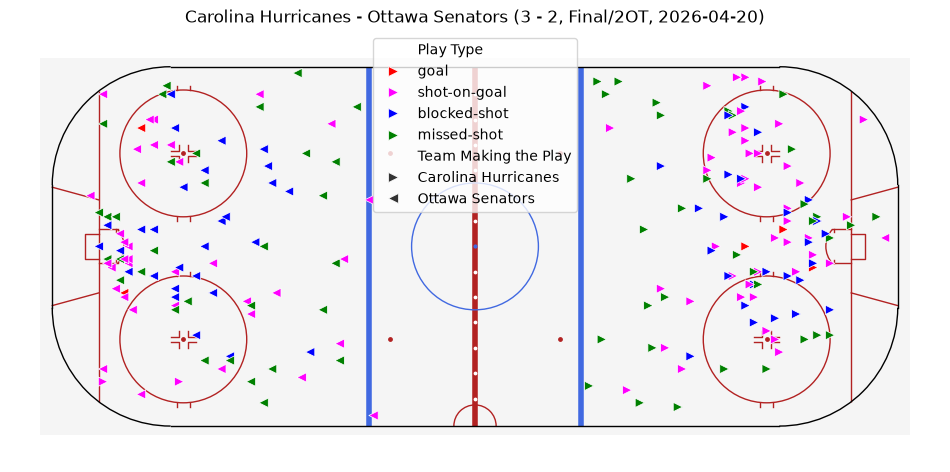

In [21]:
# все попытки бросков в матче из п. 14
m = events[(events['Game ID'] == idxmax) &
           events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])].copy()

# в нечётных периодах разворачиваем координаты, чтобы гости били влево, а хозяева вправо
odd = m['Period'] % 2 == 1
m['x'] = np.where(odd, -m['X Coordinate on the Ice Rink'], m['X Coordinate on the Ice Rink'])
m['y'] = np.where(odd, -m['Y Coordinate on the Ice Rink'], m['Y Coordinate on the Ice Rink'])

home, away = games.loc[idxmax, 'Home Team'], games.loc[idxmax, 'Away Team']

plt.figure(figsize=(12, 5.6))
plot_rink()                                                    # площадка из rink.py
sns.scatterplot(data=m, x='x', y='y',
                hue='Play Type',                               # цвет = исход броска
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette=['red', 'magenta', 'blue', 'green'],
                style='Team Making the Play',                  # форма = команда
                style_order=[home, away], markers=['>', '<'],
                s=45)
plt.axis('equal')                                              # одинаковый масштаб по осям
plt.axis('off')                                                # без осей, только площадка
plt.title(gameInfo(idxmax))
plt.show()

**Вывод.** Справа броски Carolina (►), слева Ottawa (◄). Голы забиты вблизи ворот.
Больше всего бросков из зоны перед воротами и из кругов вбрасывания, ещё часть от синей линии.
Заблокированные броски (синие) чаще на средней и дальней дистанции: там шайба летит через игроков.

## 16. Выведите список из десяти игроков, которые забили больше всех голов в плейофф

Автор гола записан в `Player in the Event #1` у событий `goal`. Считаем, сколько раз каждый игрок там встречается. При равенстве на 10-м месте показываем всех, кто его делит.

In [22]:
goal_events = events[events['Play Type'] == 'goal']                 # только голы

goals = goal_events['Player in the Event #1'].value_counts()        # сколько голов у каждого игрока
goals.nlargest(10, keep='all')                                      # топ-10 (при равенстве показываем всех)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Jordan Staal         8
Nikolaj Ehlers       8
Nathan MacKinnon     7
Taylor Hall          7
Mark Stone           7
Jackson Blake        7
Alex Newhook         7
Matt Boldy           7
Name: count, dtype: int64

**Вывод.** Больше всех забил Brett Howden (14 голов), за ним Pavel Dorofeyev (12) и Logan Stankoven (11). 7-е место с 7 голами делят шесть игроков, поэтому в списке 12 фамилий.

## 17. Выведите список из десяти игроков, которые набрали больше всех голевых передач в плей-офф

Ассистенты гола записаны в `Player in the Event #2` и `Player in the Event #3`. Объединяем оба столбца и считаем, сколько передач у каждого игрока.

In [23]:
assists = pd.concat([goal_events['Player in the Event #2'],          # первый ассистент
                     goal_events['Player in the Event #3']]          # второй ассистент
                    ).value_counts()                                 # сколько передач у каждого игрока
assists.nlargest(10, keep='all')

Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Taylor Hall        12
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Quinn Hughes       11
Kirill Kaprizov    11
Name: count, dtype: int64

**Вывод.** Больше всех передач у Jack Eichel (20) и Mitch Marner (19) из Vegas. Дальше с большим отрывом идут Jackson Blake и Lane Hutson (по 13).

## 18. Выведите список из десяти игроков, которые набрали больше всего очков по системе гол плюс пас.

Очки игрока = голы (п. 16) + передачи (п. 17). Если у игрока есть только голы или только передачи, недостающее считаем нулём.

In [24]:
points = goals.add(assists, fill_value=0).astype(int)   # голы + передачи
points.nlargest(10, keep='all')

Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Nikolaj Ehlers     18
Shea Theodore      18
Lane Hutson        16
Logan Stankoven    16
Nick Suzuki        16
Pavel Dorofeyev    16
Name: count, dtype: int64

**Вывод.** Больше всех очков у Mitch Marner (29), на втором месте Jack Eichel (22), оба из Vegas. 8-е место с 16 очками делят четверо, поэтому в списке 11 фамилий.

## 19. Выведите список из десяти игроков, которые в среднем нанесли больше всего бросков в створ ворот за одну игру.

Бросок в створ: события `shot-on-goal` и `goal`, автор броска в `Player in the Event #1`. Чтобы посчитать среднее за матч, делим число бросков игрока на число матчей, которые он сыграл. Матч считается сыгранным, если игрок хотя бы раз был на льду.

In [25]:
# сколько матчей сыграл каждый игрок: был на льду хотя бы раз
cols = [c for c in events.columns if 'on the Ice #' in c or c.endswith('Goalie')]   # все столбцы состава
appear = events.melt(id_vars='Game ID', value_vars=cols, value_name='Player').dropna()   # (матч, игрок)
games_played = appear.drop_duplicates(['Game ID', 'Player'])['Player'].value_counts()   # число матчей

# броски в створ и среднее за матч
sog = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]['Player in the Event #1'].value_counts()

table = pd.DataFrame({'Shots': sog, 'Games': games_played}).dropna()   # только игроки с бросками
table['Shots per Game'] = table['Shots'] / table['Games']
table.nlargest(10, 'Shots per Game')

,Shots,Games,Shots per Game
Jason Robertson,30.0,6,5.000
Dylan Guenther,27.0,6,4.500
Nikita Kucherov,31.0,7,4.429
Matt Boldy,48.0,11,4.364
Quinton Byfield,17.0,4,4.250
Darren Raddysh,28.0,7,4.000
Joel Eriksson Ek,24.0,6,4.000
Alex Laferriere,15.0,4,3.750
David Pastrnak,22.0,6,3.667
Nathan MacKinnon,47.0,13,3.615


**Вывод.** Больше всего бросков в створ за матч у Jason Robertson (5,0), Dylan Guenther (4,5) и Nikita Kucherov (4,4). Matt Boldy и Nathan MacKinnon держали высокий темп на протяжении 11 и 13 матчей.

## 20. Выведите список из десяти игроков, которые в среднем провели больше всего силовых приемов за одну игру

Силовой приём: событие `hit`, игрок, который его провёл, записан в `Player in the Event #1`. Делим число приёмов на число сыгранных матчей (посчитано в п. 19).

In [26]:
hits = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()   # приёмы каждого игрока

table = pd.DataFrame({'Hits': hits, 'Games': games_played}).dropna()   # только игроки с приёмами
table['Hits per Game'] = table['Hits'] / table['Games']
table.nlargest(10, 'Hits per Game')

,Hits,Games,Hits per Game
Lawson Crouse,38.0,6,6.333
Alex Turcotte,6.0,1,6.000
Alexander Petrovic,6.0,1,6.000
Yakov Trenin,51.0,9,5.667
Dylan Cozens,22.0,4,5.500
Vasily Podkolzin,32.0,6,5.333
Carl Grundstrom,15.0,3,5.000
Ivan Barbashev,110.0,22,5.000
Marcus Foligno,55.0,11,5.000
Owen Tippett,29.0,6,4.833


**Вывод.** Больше всего силовых приёмов за матч у Lawson Crouse (6,3). На 2-3 местах игроки, сыгравшие всего 1 матч (столбец `Games`), поэтому их среднее ненадёжно: один удачный матч сильно завышает результат.

## 21. Выведите список всех вратарей, которые хотя бы в одном матче не пропустили ни одного гола (даже в тех случаях, когда играли не полную игру, а выходили на замену или наоборот были заменены).

Для каждого гола находим вратаря команды, которая пропустила, и считаем пропущенные голы
каждого вратаря в каждом матче. Вратарь попадает в список, если хотя бы в одном матче
был на льду и ничего не пропустил.

В строках победных голов в овертайме составы на льду пустые. Поэтому в таких строках берём вратаря из предыдущего события того же матча.

In [27]:
# строки без составов (там записаны победные голы в овертайме): берём вратаря из предыдущего события матча
no_lineup = events["# of Away Team's Players on the Ice"] == 0
for side in ['Away', 'Home']:
    col = f"{side} Team's Goalie"
    events[f'{side} Goalie (filled)'] = events[col]
    events.loc[no_lineup, f'{side} Goalie (filled)'] = events.groupby('Game ID')[col].ffill()[no_lineup]

# кто пропустил каждый гол: вратарь команды, которая не забивала
goals = events[events['Play Type'] == 'goal']
conceded_by = np.where(goals['Team Making the Play'] == goals['Home Team'],
                       goals['Away Goalie (filled)'],      # забили хозяева: пропустил вратарь гостей
                       goals['Home Goalie (filled)'])      # забили гости: пропустил вратарь хозяев

conceded = set(zip(goals['Game ID'], conceded_by))                          # пары (матч, вратарь), кто пропускал
played = (set(zip(events['Game ID'], events["Away Team's Goalie"])) |       # пары (матч, вратарь), кто играл
          set(zip(events['Game ID'], events["Home Team's Goalie"])))

shutouts = played - conceded                                                # играл, но не пропускал
sorted({goalie for game, goalie in shutouts if pd.notna(goalie)})           # список вратарей без повторов

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

**Вывод.** Таких вратарей 6: Vasilevskiy, Bussi, Vladar, Andersen, Korpisalo, Wedgewood.

## 22. Свой вопрос: есть ли в плей-офф преимущество своей площадки?

Принято считать, что дома играть легче. Проверим, так ли это в плей-офф 2026: как часто выигрывают хозяева и сколько они забивают по сравнению с гостями.

Хозяева выиграли: 39 из 82 (47.6%)
Среднее голов за матч: хозяева 2.8 | гости 3.12


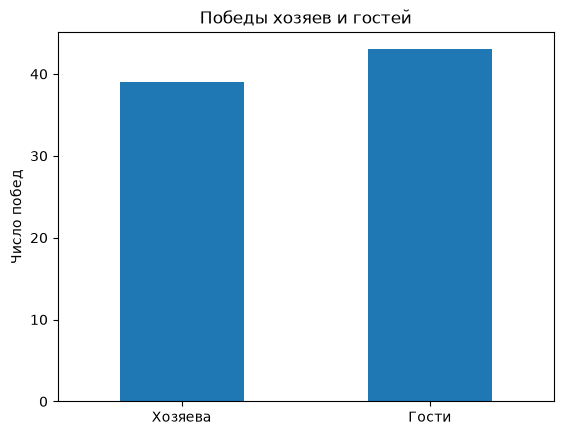

In [28]:
home_win = games['Home Score'] > games['Away Score']        # True, если выиграли хозяева

print('Хозяева выиграли:', home_win.sum(), 'из', len(games), f'({home_win.mean():.1%})')
print('Среднее голов за матч: хозяева', round(games['Home Score'].mean(), 2),
      '| гости', round(games['Away Score'].mean(), 2))

# наглядно: сколько матчей выиграли хозяева и гости
pd.Series({'Хозяева': home_win.sum(), 'Гости': (~home_win).sum()}).plot.bar(rot=0)
plt.ylabel('Число побед')
plt.title('Победы хозяев и гостей')
plt.show()

**Вывод.** Преимущества своей площадки в этом плей-офф нет. Хозяева выиграли только 39 матчей из 82 (47,6 %) и забивали в среднем даже меньше гостей (2,8 против 3,1 гола за матч). В плей-офф встречаются сильные команды, и домашний лёд почти ничего не добавляет.